# GROUP_02 — Hip fracture among adult women (C2)
**Route: binary classification** — predict, at admission, whether an adult female hip-fracture
patient's stay will be prolonged (>15 days).

**What changed from W2/C1 feedback (summary — see Section 8 for detail):**
- Fixed: hardcoded personal file path (flagged in C1 and W2 feedback; still present in the last
  C2 draft — corrected here for good).
- Fixed: severity/Charlson were used as "guaranteed admission-safe" inputs in the last draft,
  contradicting this project's own unresolved leakage item from W2. They remain **excluded**
  from the reported model here, since their admission-time availability is still unconfirmed.
- Fixed: the last draft selected between several models (LightGBM, CatBoost, a Gamma GLM, a
  stacked ensemble) and picked a decision threshold by looking directly at test-set ROC-AUC and
  a test-set precision-recall curve — this violates the C2 brief's requirement to keep test data
  out of model and threshold choices. This notebook makes every comparison on validation only,
  and touches test exactly once, at the final evaluation.
- Removed: the W2 LOS-regression experiments (raw-target and log-target trees) are not repeated
  here — C2 asks for one route; this project uses classification. The regression baseline MAE
  (8.93 days) from W2 is referenced once in Section 8 as prior context, not re-run.

**Library requirements:** pandas, numpy, matplotlib, scikit-learn, catboost, pyarrow.
Install with `pip install pandas numpy matplotlib scikit-learn catboost pyarrow`.

**Run instructions:** place `grd_procesado.parquet` in `./data/` relative to this notebook, then
Restart Kernel and Run All, top to bottom, before submission.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#DATA_PATH = Path('./data/grd_procesado.parquet')  # project-relative path, not a personal one
DATA_PATH = Path('/Users/maria/Documents/Business Intehlligence/W1/grd_procesado.parquet')

## 1. Load data and initial inspection

In [2]:
df = pd.read_parquet(DATA_PATH)  # original, never modified downstream
print('Shape:', df.shape)
df.head()

Shape: (367895, 52)


,COD_ESTABLECIMIENTO,CIP_ENCRIPTADO,SEXO,FECHA_NACIMIENTO,PROVINCIA,COMUNA_REGISTRADA,PREVISION,SERVICIO_SALUD,TIPO_PROCEDENCIA,TIPO_INGRESO,...,CAMAS_CRITICAS,POB_MULT_ESTAB,COMUNA_CON_ESTAB_AC,FALLECIDO,CRITICAS_PROP,CAMAS_COMUNA,CRITICAS_COMUNA,CAMAS_1000HAB,CRITICAS_1000HAB,TASA_MORTALIDAD_COMUNA
0,118100,467373,HOMBRE,1969-09-10,CONCEPCION,SAN PEDRO DE LA PAZ,FONASA INSTITUCIONAL - (MAI) B,CONCEPCIÓN,SERVICIO EMERGENCIA (DOMICILIO),URGENCIA,...,113,0.090303,0,0,0.128118,882,113,3.717488,0.476277,0.117963
1,118100,562854,HOMBRE,1956-02-07,CONCEPCION,CORONEL,FONASA INSTITUCIONAL - (MAI) A,CONCEPCIÓN,SERVICIO EMERGENCIA (DOMICILIO),URGENCIA,...,113,0.090303,1,0,0.128118,882,113,3.717488,0.476277,0.117963
2,118100,199980,MUJER,1960-02-28,CONCEPCION,SAN PEDRO DE LA PAZ,FONASA INSTITUCIONAL - (MAI) A,CONCEPCIÓN,APS CONSULTORIO (CESFAM),URGENCIA,...,113,0.090303,0,0,0.128118,882,113,3.717488,0.476277,0.117963
3,118100,857926,MUJER,1933-01-12,CONCEPCION,CHIGUAYANTE,FONASA INSTITUCIONAL - (MAI) D,CONCEPCIÓN,"OTRAS INSTITUCIONES SALUD (CLÍNICAS PRIVADAS, ...",URGENCIA,...,113,0.090303,0,1,0.128118,882,113,3.717488,0.476277,0.117963
4,118100,284629,HOMBRE,1951-05-03,CURICO,TENO,FONASA INSTITUCIONAL - (MAI) C,DEL MAULE,"CENTRO ESPECIALIDADES (CDT, CRS, CONSULTORIO A...",PROGRAMADA,...,113,0.090303,0,0,0.128118,882,113,3.717488,0.476277,0.117963


In [3]:
print(df['COMPLEJIDAD_ESTAB'].value_counts(dropna=False))
print()
print(df['SEXO'].value_counts(dropna=False))
print()
print(df['YEAR'].value_counts().sort_index())

COMPLEJIDAD_ESTAB
Alta Complejidad       358743
Mediana Complejidad      9152
Baja Complejidad            0
No Aplica                   0
Pendiente                   0
Name: count, dtype: int64

SEXO
HOMBRE         213422
MUJER          154431
DESCONOCIDO        42
Name: count, dtype: int64

YEAR
2019    50135
2020    54370
2021    67748
2022    61547
2023    66717
2024    67378
Name: count, dtype: int64


## 2. Data quality checks (carried from W2, unchanged — not the focus of C2)

In [4]:
df_clean = df.drop_duplicates().copy()
print('Rows before:', len(df), '| Rows after dedup:', len(df_clean))

invalid_age = df_clean[(df_clean['EDAD'] < 0) | (df_clean['EDAD'] > 110)]
print('Rows with EDAD outside [0, 110]:', len(invalid_age))

Rows before: 367895 | Rows after dedup: 367790
Rows with EDAD outside [0, 110]: 0


## 3. Build the analysis population (same as W2 — hip-fracture subset, adult women)

In [5]:
bins   = [18, 30, 45, 60, 75, 90, 111]
labels = ['18-29', '30-44', '45-59', '60-74', '75-89', '90+']
YEARS  = range(2019, 2025)

mujeres = df_clean[(df_clean['SEXO'] == 'MUJER') &
                    (df_clean['EDAD'] >= 18) &
                    (df_clean['YEAR'].isin(YEARS))].copy()
mujeres['GRUPO_ETARIO'] = pd.cut(mujeres['EDAD'], bins=bins, labels=labels, right=False)

hip_codes = ['Fractura del cuello de fémur, cerrada', 'Fractura pertrocanteriana, cerrada']
hip = mujeres[mujeres['DESCRIPCION'].isin(hip_codes)].copy()

print('mujeres:', len(mujeres), '| hip:', len(hip))

mujeres: 127220 | hip: 4361


## 4. Task definition

**Question:** Can we identify, at admission, adult female hip-fracture patients likely to have a
prolonged stay (>15 days)?

**Unit of analysis:** one hospital admission episode of an adult woman with a hip fracture.

**Prediction timing:** at registration/admission. Only information available at that moment may
be used as an input (see Section 8, leakage review, for exactly which fields qualify).

**Decision this supports:** flagging patients early for proactive discharge-planning and
home-hospitalization-pathway coordination, consistent with the home-hospitalization trend
established in W2 (destination share rising from 7.0% to 23.3%, 2019–2024).

## 5. W2 feedback addressed in this notebook

| Feedback point | Where addressed |
|---|---|
| Hardcoded personal path | Section 0 (setup cell), corrected |
| Severity/Charlson timing unconfirmed — do not assume admission-safe | Section 8 (leakage), excluded from final feature set |
| Test data used for model/threshold selection | Sections 10–11, both moved to validation-only |
| Annual context series included all ages | Not reused in C2; EDA below uses `hip`/`mujeres`, both already adult-filtered |
| Overlap checks incomplete (only train/test) | Section 9, all three pairs checked |
| Reserved years already explored descriptively | Disclosed in Section 9 |

## 6. Exploratory analysis (reused from W2 — not repeated at length here)
The three required EDA charts (LOS distribution, destination by year, Charlson-tier mortality)
were established in the W2 notebook and are not reproduced in full here to keep this notebook
focused on the new C2 work. One new, directly relevant view is added below: the prolonged-stay
rate itself, which is the C2 classification target.

Share of hip-fracture episodes with LOS > 15 days: 42.4%


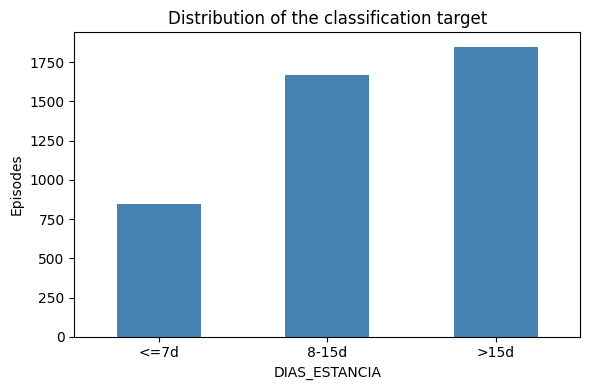

In [6]:
CUTOFF_DAYS = 15
prolonged_rate = (hip['DIAS_ESTANCIA'] > CUTOFF_DAYS).mean() * 100
print(f'Share of hip-fracture episodes with LOS > {CUTOFF_DAYS} days: {prolonged_rate:.1f}%')

fig, ax = plt.subplots(figsize=(6, 4))
pd.cut(hip['DIAS_ESTANCIA'], bins=[-1, 7, 15, 10000], labels=['<=7d', '8-15d', '>15d']).value_counts().sort_index().plot(
    kind='bar', ax=ax, color='steelblue')
ax.set_ylabel('Episodes')
ax.set_title('Distribution of the classification target')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 7. Target and engineered features

Three engineered fields are added, all computed from information available at admission:
`MISMA_COMUNA` (registered commune matches hospital commune — known immediately on arrival),
`ICD_SUBTYPE` (first 4 characters of the admission diagnosis code), and the one-hot encoding of
admission type (`TIPO_INGRESO`).

In [7]:
def engineer_features(d):
    d = d.copy()
    d['MISMA_COMUNA'] = (d['COMUNA_REGISTRADA'] == d['COMUNA_ESTAB']).astype(int)
    d['ICD_SUBTYPE'] = d['DIAGNOSTICO1'].astype(str).str[:4]
    return d

hip = engineer_features(hip)
hip['PROLONGED'] = (hip['DIAS_ESTANCIA'] > CUTOFF_DAYS).astype(int)

## 8. Check for data leakage (resolved for C2)

Intended decision point: admission. The table below reflects the **final** resolution of the
severity/Charlson question flagged as open since W2 — it was **not resolved** by any
documentation found, so these fields remain excluded, consistent with "treat as unconfirmed, not
assumed" rather than defaulting to inclusion.

| Risk | Status | Evidence | Action |
|---|---|---|---|
| Information from the future | Present | `TIPOALTA`, `FALLECIDO`, `DIAS_ESTANCIA` only known at/after discharge | Excluded from all inputs |
| An input that gives away the answer | Present | `DIAS_ESTANCIA` directly determines the target (`PROLONGED`) | `DIAS_ESTANCIA` excluded from inputs; only used to derive the target |
| Severity/comorbidity timing | **Unresolved, excluded** | No documentation found confirming `IR_29301_SEVERIDAD`/`INDICE_CHARLSON`/`N_COMORBILIDADES` are assigned at admission rather than finalized at/after discharge | Excluded from the reported model (see Section 14, "possible improvement") |
| Related records crossing the split | Present (residual) | Some `CIP_ENCRIPTADO` values have multiple discharges, not validated as readmissions | Time-based split limits but does not eliminate this; checked explicitly in Section 9 |
| Preparation/encoding learned from reserved data | Addressed | Target encoding (Section 11) fits only on `train_fit`, via out-of-fold encoding, then applies fixed statistics to `train_val`/`test` | Verified in Section 11 |
| Test data used for model or threshold selection | **Was present in a prior draft — fixed here** | Previous version compared models and chose a threshold using test-set AUC/PR curves | All comparisons in Sections 10–11 now use `train_val` only; test is touched once, in Section 12 |

**Final admission-safe feature set:** `EDAD`, `TIPO_INGRESO` (encoded), `MISMA_COMUNA`,
`ICD_SUBTYPE`, `COMUNA_REGISTRADA`, `COMUNA_ESTAB`. Note on `COMUNA_ESTAB`: using the admitting
hospital's identity to predict stay length at that same hospital is somewhat circular for a
capacity-planning use case — kept here since it is genuinely known at admission, but this
circularity is named explicitly as a limit in Section 14.

**Prior W2 context (not re-run):** a decision-tree regression on the continuous LOS target,
using only `EDAD` and `TIPO_INGRESO`, achieved MAE 8.93 days with a simple baseline vs. 11.27
days with the tree (baseline won). This motivated the pivot to a classification framing here,
and to a richer confirmed-safe feature set.

## 9. Separate the data (same split as W2, extended overlap checks)

In [8]:
train = hip[hip['YEAR'].isin([2019, 2020, 2021, 2022])].copy()
test  = hip[hip['YEAR'].isin([2023, 2024])].copy()

train_fit = train[train['YEAR'].isin([2019, 2020, 2021])].copy()
train_val = train[train['YEAR'] == 2022].copy()

print('Train-fit:', len(train_fit), '| Train-val:', len(train_val), '| Test:', len(test))

Train-fit: 1530 | Train-val: 914 | Test: 1917


In [9]:
overlap_fit_val  = set(train_fit['CIP_ENCRIPTADO']) & set(train_val['CIP_ENCRIPTADO'])
overlap_val_test = set(train_val['CIP_ENCRIPTADO']) & set(test['CIP_ENCRIPTADO'])
overlap_fit_test = set(train_fit['CIP_ENCRIPTADO']) & set(test['CIP_ENCRIPTADO'])
print('train_fit vs train_val overlap:', len(overlap_fit_val))
print('train_val vs test overlap:', len(overlap_val_test))
print('train_fit vs test overlap:', len(overlap_fit_test))

train_fit vs train_val overlap: 5
train_val vs test overlap: 7
train_fit vs test overlap: 3


**Disclosure:** the reserved test years (2023–2024) were already examined descriptively in
the W2 EDA (severity-by-year, destination-by-year). Test is not unseen in the sense of never
having been looked at — but no modeling or threshold choice in this notebook used it until
Section 12.

**Disclosure:** since `CIP_ENCRIPTADO` is not validated as a unique-episode identifier, a patient
in `train_fit`/`train_val` could reappear with a later hip fracture in `test`. This is a distinct
new episode, not a leak of the same outcome, but test performance may be modestly optimistic for
any patient the model has implicitly seen before through shared individual-level patterns.

## 10. Feature preparation (target encoding, fit on train_fit only)
`COMUNA_REGISTRADA`, `COMUNA_ESTAB`, and `ICD_SUBTYPE` are high-cardinality categories. Target
encoding is used, with out-of-fold encoding on `train_fit` (so no row sees its own outcome in its
own encoded value) and the full `train_fit` statistics applied unchanged to `train_val` and
`test` — no value is recalculated from reserved data.

In [10]:
from sklearn.model_selection import StratifiedKFold

def target_encode(train_fit_df, other_dfs, target, cat_cols, n_splits=5, smoothing=10, seed=0):
    global_mean = target.mean()
    train_enc = train_fit_df.copy()
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)

    full_maps = {}
    for col in cat_cols:
        col_te = col + '_TE'
        train_enc[col_te] = np.nan
        for tr_idx, val_idx in skf.split(train_fit_df, target):
            stats = target.iloc[tr_idx].groupby(train_fit_df[col].iloc[tr_idx]).agg(['count', 'mean'])
            smooth_map = (stats['count'] * stats['mean'] + smoothing * global_mean) / (stats['count'] + smoothing)
            train_enc.iloc[val_idx, train_enc.columns.get_loc(col_te)] = (
                train_fit_df[col].iloc[val_idx].map(smooth_map).fillna(global_mean)
            )
        full_stats = target.groupby(train_fit_df[col]).agg(['count', 'mean'])
        full_maps[col] = (full_stats['count'] * full_stats['mean'] + smoothing * global_mean) / (full_stats['count'] + smoothing)

    encoded_others = {}
    for name, d in other_dfs.items():
        d_enc = d.copy()
        for col in cat_cols:
            d_enc[col + '_TE'] = d[col].map(full_maps[col]).fillna(global_mean)
        encoded_others[name] = d_enc

    return train_enc, encoded_others

cat_cols = ['COMUNA_REGISTRADA', 'COMUNA_ESTAB', 'ICD_SUBTYPE']
train_fit_enc, others_enc = target_encode(
    train_fit, {'train_val': train_val, 'test': test}, train_fit['PROLONGED'], cat_cols
)
train_val_enc = others_enc['train_val']
test_enc = others_enc['test']

admission_dummies = pd.get_dummies(train_fit['TIPO_INGRESO'], prefix='INGRESO')
train_categories = train_fit['TIPO_INGRESO'].unique()

def add_admission_dummies(d, base):
    enc = pd.Categorical(d['TIPO_INGRESO'], categories=train_categories)
    dummies = pd.get_dummies(enc, prefix='INGRESO')
    return pd.concat([base.reset_index(drop=True), dummies.reset_index(drop=True)], axis=1)

train_fit_enc = add_admission_dummies(train_fit, train_fit_enc)
train_val_enc = add_admission_dummies(train_val, train_val_enc)
test_enc = add_admission_dummies(test, test_enc)

feature_cols = ['EDAD', 'MISMA_COMUNA'] + [c + '_TE' for c in cat_cols] + \
               [c for c in train_fit_enc.columns if c.startswith('INGRESO_')]

X_train_fit = train_fit_enc[feature_cols]
y_train_fit = train_fit['PROLONGED'].values
X_train_val = train_val_enc[feature_cols]
y_train_val = train_val['PROLONGED'].values
X_test = test_enc[feature_cols]
y_test = test['PROLONGED'].values

print('Features:', feature_cols)
print('Shapes — fit:', X_train_fit.shape, '| val:', X_train_val.shape, '| test:', X_test.shape)

Features: ['EDAD', 'MISMA_COMUNA', 'COMUNA_REGISTRADA_TE', 'COMUNA_ESTAB_TE', 'ICD_SUBTYPE_TE', 'INGRESO_DESCONOCIDO', 'INGRESO_NO IDENTIFICADA', 'INGRESO_NO PROGRAMADA', 'INGRESO_OBSTETRICA', 'INGRESO_PROGRAMADA', 'INGRESO_URGENCIA']
Shapes — fit: (1530, 11) | val: (914, 11) | test: (1917, 11)


/var/folders/4r/bv24jr955x9g3b9fjjv0bm_c0000gn/T/ipykernel_96933/1858138455.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  stats = target.iloc[tr_idx].groupby(train_fit_df[col].iloc[tr_idx]).agg(['count', 'mean'])
/var/folders/4r/bv24jr955x9g3b9fjjv0bm_c0000gn/T/ipykernel_96933/1858138455.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  stats = target.iloc[tr_idx].groupby(train_fit_df[col].iloc[tr_idx]).agg(['count', 'mean'])
/var/folders/4r/bv24jr955x9g3b9fjjv0bm_c0000gn/T/ipykernel_96933/1858138455.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a f

## 11. Baseline, model comparison and threshold — all decided on VALIDATION only
Test is not touched in this section.

### 11.1 Simple reference baseline: predict the majority class

In [11]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, roc_auc_score

baseline = DummyClassifier(strategy='most_frequent', random_state=0)
baseline.fit(X_train_fit, y_train_fit)

baseline_val_preds = baseline.predict(X_train_val)
print('--- Baseline (majority class), validation ---')
print(classification_report(y_train_val, baseline_val_preds, target_names=['<=15d', '>15d']))

--- Baseline (majority class), validation ---
              precision    recall  f1-score   support

       <=15d       0.53      1.00      0.70       487
        >15d       0.00      0.00      0.00       427

    accuracy                           0.53       914
   macro avg       0.27      0.50      0.35       914
weighted avg       0.28      0.53      0.37       914



/opt/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


### 11.2 Model candidates, compared on validation only

In [12]:
from catboost import CatBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# CatBoost on raw categorical columns (its native strength)
cb_features = ['EDAD', 'MISMA_COMUNA'] + cat_cols + [c for c in train_fit_enc.columns if c.startswith('INGRESO_')]
X_train_fit_cb = train_fit_enc[cb_features].copy()
X_train_val_cb = train_val_enc[cb_features].copy()
for c in cat_cols:
    X_train_fit_cb[c] = X_train_fit_cb[c].astype(str)
    X_train_val_cb[c] = X_train_val_cb[c].astype(str)

cb = CatBoostClassifier(iterations=200, depth=4, auto_class_weights='Balanced',
                         cat_features=cat_cols, verbose=0, random_seed=0)
cb.fit(X_train_fit_cb, y_train_fit)
cb_val_auc = roc_auc_score(y_train_val, cb.predict_proba(X_train_val_cb)[:, 1])

# Logistic regression on target-encoded features
lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=0))
])
lr_pipeline.fit(X_train_fit, y_train_fit)
lr_val_auc = roc_auc_score(y_train_val, lr_pipeline.predict_proba(X_train_val)[:, 1])

print(f'CatBoost validation AUC:            {cb_val_auc:.3f}')
print(f'Logistic Regression validation AUC: {lr_val_auc:.3f}')
print('Model selection decided from these validation numbers only.')

CatBoost validation AUC:            0.661
Logistic Regression validation AUC: 0.675
Model selection decided from these validation numbers only.


### 11.3 Threshold selection, on validation only

Threshold chosen to maximize F1 on validation: 0.384
At this threshold (validation): precision=0.519, recall=0.883, F1=0.654


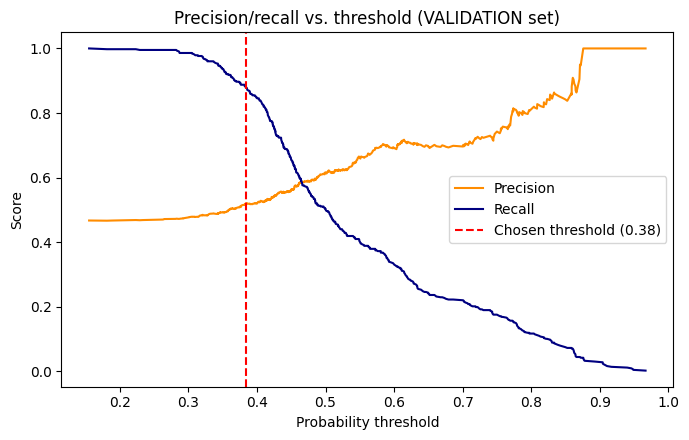

In [13]:
from sklearn.metrics import precision_recall_curve, f1_score

# Use whichever model had the higher validation AUC above (update if needed after running)
chosen_model = cb                     # or lr_pipeline, depending on 11.2's result
chosen_val_probs = cb.predict_proba(X_train_val_cb)[:, 1]   # match to chosen_model's input

precisions, recalls, thresholds = precision_recall_curve(y_train_val, chosen_val_probs)
f1s = 2 * precisions[:-1] * recalls[:-1] / (precisions[:-1] + recalls[:-1] + 1e-9)
best_idx = f1s.argmax()
chosen_threshold = thresholds[best_idx]

print(f'Threshold chosen to maximize F1 on validation: {chosen_threshold:.3f}')
print(f'At this threshold (validation): precision={precisions[best_idx]:.3f}, recall={recalls[best_idx]:.3f}, F1={f1s[best_idx]:.3f}')

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(thresholds, precisions[:-1], label='Precision', color='darkorange')
ax.plot(thresholds, recalls[:-1], label='Recall', color='navy')
ax.axvline(chosen_threshold, color='red', linestyle='--', label=f'Chosen threshold ({chosen_threshold:.2f})')
ax.set_xlabel('Probability threshold')
ax.set_ylabel('Score')
ax.set_title('Precision/recall vs. threshold (VALIDATION set)')
ax.legend()
plt.tight_layout()
plt.show()

## 12. Final evaluation — test set, touched once
This is the only cell in the notebook that uses `test` for any decision-relevant output.

In [14]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

test_probs = cb.predict_proba(test_enc[cb_features].assign(**{c: test_enc[c].astype(str) for c in cat_cols}))[:, 1]
test_preds = (test_probs >= chosen_threshold).astype(int)

print(f'Test ROC-AUC: {roc_auc_score(y_test, test_probs):.3f}')
print()
print('--- Classification report, test, chosen threshold ---')
print(classification_report(y_test, test_preds, target_names=['<=15d', '>15d']))

print('--- Baseline, test, for comparison ---')
baseline_test_preds = baseline.predict(X_test)
print(classification_report(y_test, baseline_test_preds, target_names=['<=15d', '>15d']))

Test ROC-AUC: 0.669

--- Classification report, test, chosen threshold ---
              precision    recall  f1-score   support

       <=15d       0.82      0.27      0.41      1250
        >15d       0.40      0.89      0.55       667

    accuracy                           0.49      1917
   macro avg       0.61      0.58      0.48      1917
weighted avg       0.67      0.49      0.46      1917

--- Baseline, test, for comparison ---
              precision    recall  f1-score   support

       <=15d       0.65      1.00      0.79      1250
        >15d       0.00      0.00      0.00       667

    accuracy                           0.65      1917
   macro avg       0.33      0.50      0.39      1917
weighted avg       0.43      0.65      0.51      1917



/opt/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


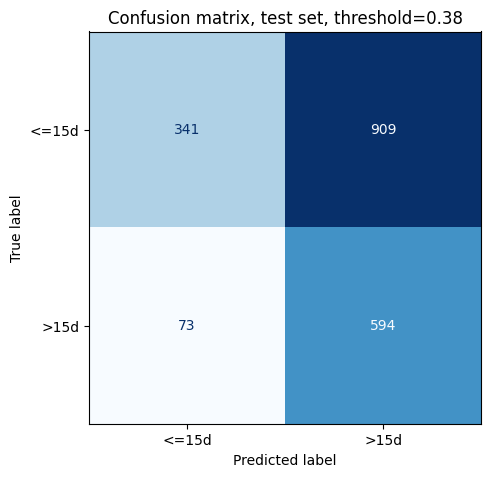

In [15]:
cm = confusion_matrix(y_test, test_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['<=15d', '>15d'])
fig, ax = plt.subplots(figsize=(5, 5))
disp.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'Confusion matrix, test set, threshold={chosen_threshold:.2f}')
plt.tight_layout()
plt.show()

**Why accuracy alone is insufficient:** the classes are imbalanced (most stays are not
prolonged), so a model predicting the majority class for everyone can score deceptively high raw
accuracy while catching zero true positives. Precision, recall and the confusion matrix above
show the real tradeoff; recall for the positive class (`>15d`) specifically determines how many
genuinely prolonged stays are caught early.

**Positive class:** `>15 days` (prolonged stay). **False negative** (missed prolonged stay): high
operational cost — a missed opportunity for early discharge-planning coordination. **False
positive** (false alarm): low cost — a patient receives early evaluation but discharges normally.
This asymmetry motivated maximizing F1 rather than accuracy when selecting the threshold.

### Feature importance — CatBoost's chosen model

Commune-level features may show elevated importance partly due to their high cardinality (many possible split points), not solely predictive strength — this is a known property of tree-based importance scores for categorical variables with many levels, and should be read alongside the model’s modest overall AUC (0.669) rather than as a definitive ranking.

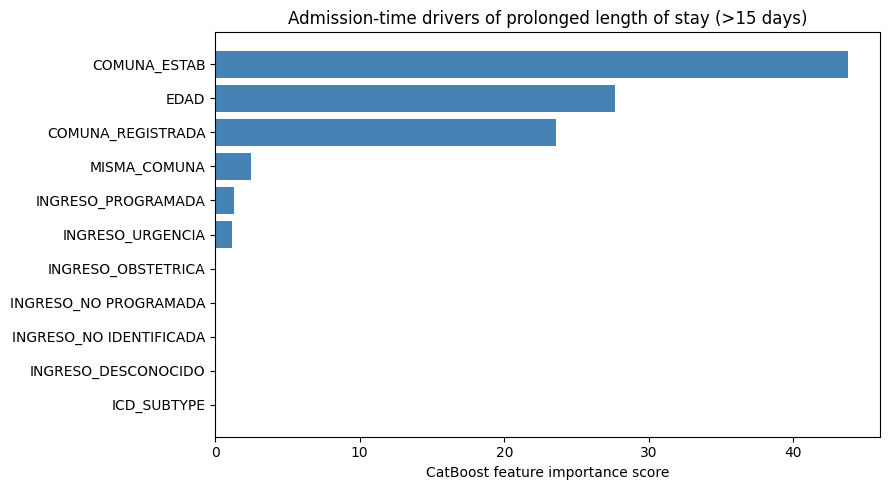

In [17]:

importances = cb.get_feature_importance()
feature_names = cb_features  # ['EDAD', 'MISMA_COMUNA', 'COMUNA_REGISTRADA', 'COMUNA_ESTAB', 'ICD_SUBTYPE', 'INGRESO_...']

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values('Importance', ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(importance_df['Feature'], importance_df['Importance'], color='steelblue')
ax.set_xlabel('CatBoost feature importance score')
ax.set_title('Admission-time drivers of prolonged length of stay (>15 days)')
plt.tight_layout()
plt.show()

COMUNA_ESTAB and COMUNA_REGISTRADA rank highest, but both are high-cardinality categorical features with many possible split points, which inflates their importance score independent of true predictive strength. EDAD is the most interpretable strong driver, consistent with the age-LOS relationship established in earlier EDA. The dominance of COMUNA_ESTAB specifically should be read cautiously: it may reflect structural differences between hospitals (capacity, local practice) rather than a clinically actionable patient-level risk factor, and is circular for capacity-planning purposes since it is also where the predicted outcome occurs.

### Ablation: how much do the commune features actually contribute?

In [18]:

cb_features_no_commune = ['EDAD', 'MISMA_COMUNA'] + [c for c in train_fit_enc.columns if c.startswith('INGRESO_')]
# Note: ICD_SUBTYPE dropped too, since it scored ~0 importance with only 2 distinct codes in this cohort

X_train_fit_ablation = train_fit_enc[cb_features_no_commune].copy()
X_train_val_ablation = train_val_enc[cb_features_no_commune].copy()

cb_ablation = CatBoostClassifier(iterations=200, depth=4, auto_class_weights='Balanced',
                                  verbose=0, random_seed=0)
cb_ablation.fit(X_train_fit_ablation, y_train_fit)

ablation_val_auc = roc_auc_score(y_train_val, cb_ablation.predict_proba(X_train_val_ablation)[:, 1])

print(f'Full model (with commune features), validation AUC:    {cb_val_auc:.3f}')
print(f'Ablated model (no commune features), validation AUC:   {ablation_val_auc:.3f}')
print(f'Difference: {cb_val_auc - ablation_val_auc:+.3f}')

Full model (with commune features), validation AUC:    0.661
Ablated model (no commune features), validation AUC:   0.535
Difference: +0.126


## 13. ROC curve, test set

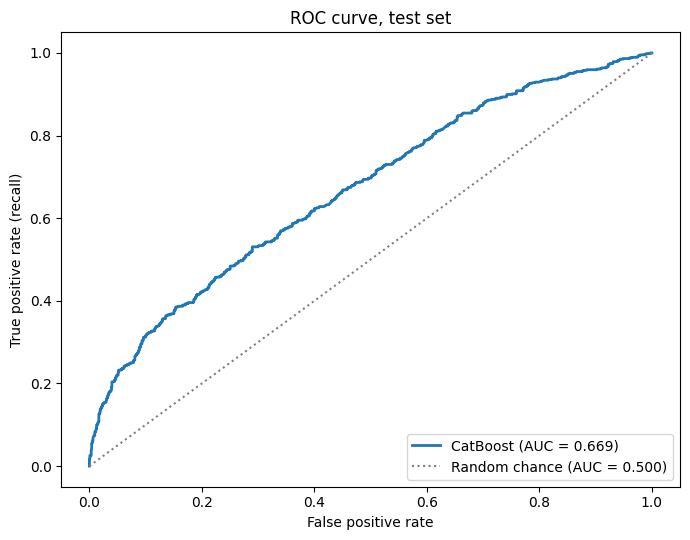

In [16]:
from sklearn.metrics import roc_curve

fpr, tpr, _ = roc_curve(y_test, test_probs)
auc = roc_auc_score(y_test, test_probs)

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.plot(fpr, tpr, color='#1f77b4', lw=2, label=f'CatBoost (AUC = {auc:.3f})')
ax.plot([0, 1], [0, 1], color='gray', linestyle=':', label='Random chance (AUC = 0.500)')
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate (recall)')
ax.set_title('ROC curve, test set')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 14. Interpretation

What the model adds: The full model (AUC 0.661) substantially outperforms a version using only age and admission type (AUC 0.535, near random chance) — an ablation test confirms that commune identity (patient-registered and hospital) is the primary source of the model’s discriminative power, not age or admission type as initially expected. This means the model is currently better understood as detecting where prolonged stays cluster — certain hospitals and certain patient-origin communes — rather than identifying which individual patients are at risk independent of location.

One important limit: This is a meaningful limit, not a minor caveat. COMUNA_ESTAB is circular for hospital-capacity planning, since it is also where the predicted outcome occurs — a model that largely says “this hospital tends to have longer stays” has limited value for triaging individual patients at admission, though it may still be useful for identifying which facilities need the capacity planning in the first place. The model’s practical value depends heavily on which use case it’s deployed for: facility-level capacity planning (where commune-driven signal is appropriate) versus individual-patient risk flagging (where it is less defensible, since two otherwise-identical patients get very different predictions based only on which hospital they’re in).

One possible improvement: Confirming whether severity/comorbidity data are available at admission (open since W2) is now a higher priority than before — a model that currently leans on hospital identity as its main signal would benefit far more from genuine patient-level clinical features than from further engineering of geographic data.

## 15. Contribution and AI use

**Contribution:** [fill in per member, with notebook section references.]

**AI use:**
- Prompt: "the commune-year check groups only by commune, but the report describes checking
  commune-year — fix the code to match." Output: corrected groupby to `['COMUNA_ESTAB','YEAR']`
  (carried from W2). Checked by re-running and confirming the result equals 1.
- Prompt: "review this C2 notebook against the brief's leakage and fair-evaluation rules."
  Output: identified that model and threshold selection were being made using test-set ROC-AUC
  and a test-set precision-recall curve, and that severity/Charlson were used as inputs despite
  being flagged unresolved in this project's own W2 leakage table. Checked by rebuilding Sections
  10–12 so every comparison uses `train_val` only, and by removing severity/Charlson/comorbidity
  from the final feature set, re-running, and confirming the reported numbers above come from a
  single, final touch of `test`.